# Uplift Decision Lab

An evidence walkthrough: experiment quality → average effect → ranking → business decision. Run `uv run python run.py` from the repository first. This notebook reads generated evidence; it does not tune models on test. No personal work experience is invented.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "run.py").exists() else Path.cwd().parent
REPORTS = ROOT / "reports"
summary = json.loads((REPORTS / "summary.json").read_text())

## 1. Can we trust the extract?
SRM is an alarm, not proof of randomization. Balance is descriptive. Identical feature profiles are not duplicate customer IDs; we retain them.

In [2]:
display(summary["quality"])
display(summary["randomization"])
display(pd.read_csv(REPORTS / "balance.csv"))

{'rows': 64000,
 'missing_cells': 0,
 'duplicate_profiles': 7791,
 'duplicate_full_rows': 6562,
 'note': 'No customer ID: identical profiles are flagged, never automatically removed.'}

{'counts': {'Mens E-Mail': 21307, 'Womens E-Mail': 21387, 'No E-Mail': 21306},
 'srm_chi2': 0.20253125000000002,
 'srm_p_value': 0.9036929575604196,
 'expected_allocation': '1:1:1',
 'srm_flag': False}

,feature,smd
0,recency,0.006832
1,history_segment=1) $0 - $100,0.010917
2,history_segment=2) $100 - $200,-0.016360
3,history_segment=3) $200 - $350,0.005471
4,history_segment=4) $350 - $500,-0.004257
5,history_segment=5) $500 - $750,-0.009740
6,"history_segment=6) $750 - $1,000",0.006073
7,"history_segment=7) $1,000 +",0.015835
8,history,0.007613
9,mens,-0.004582


## 2. Did the email change purchases?
Primary outcome is purchase within two weeks. Visits are secondary. ATE uses randomized assignment; the full-sample estimate is descriptive and is not used to select the model.

In [3]:
display(
    pd.DataFrame(
        {k: summary[k] for k in ["ate_conversion", "ate_visit_secondary", "ate_spend_revenue"]}
    ).T
)
display(summary["split_sizes"])

,control_rate,treatment_rate,ate,ci_low,ci_high,n_control,n_treatment
ate_conversion,0.005726,0.012531,0.006805,0.005000,0.008610,21306.0,21307.0
ate_visit_secondary,0.106167,0.182757,0.076590,0.069953,0.083226,21306.0,21307.0
ate_spend_revenue,0.652789,1.422617,0.769827,0.485149,1.054505,21306.0,21307.0


{'train': 25567, 'validation': 8523, 'test': 8523}

## 3. Does a model rank treatment effects well?
S/T learners use CatBoost through scikit-uplift. The response baseline learns purchase propensity on controls. Qini and AUUC below are normalized scores; they are not expected profits.

,model,qini_auc_normalized,auuc_normalized,uplift_at_20pct
0,s_learner,0.061327,0.002110,0.010959
1,t_learner,0.024359,0.000807,0.012566
2,response_baseline,0.058074,0.002161,0.007565


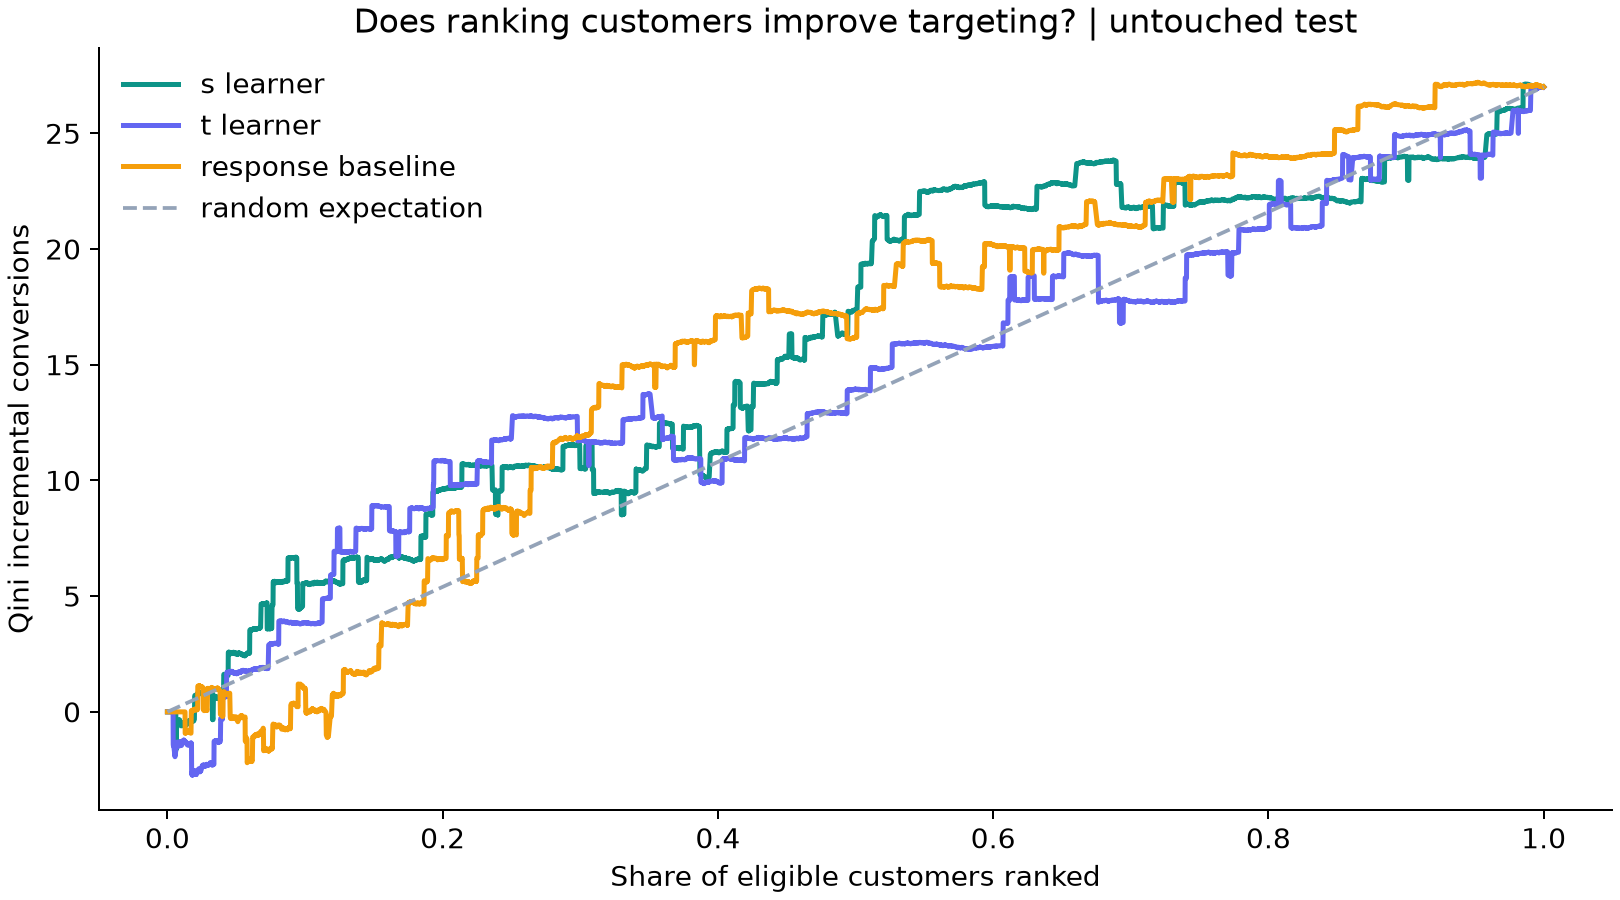

In [4]:
display(pd.read_csv(REPORTS / "ranking_metrics.csv"))
display(Image(filename=str(REPORTS / "figures/qini.png")))

## 4. Which decision was locked?
Model and coverage were selected on validation net value. Do not use the following holdout diagnostics to select a new policy. Assumptions: contribution per incremental purchase and cost per intended contact.

{'seed': 42,
 'iterations': 250,
 'value': 50.0,
 'cost': 0.1,
 'fractions': [0.1, 0.2, 0.3, 0.5, 0.7, 1.0],
 'propensity': 0.5}

{'policy': 'all',
 'fraction': 1.0,
 'net_per_customer': 0.2871876099964804,
 'ci_low': 0.07532033361437329,
 'ci_high': 0.4990548863785875,
 'net_per_1000': 287.18760999648043,
 'coverage': 1.0,
 'incremental_conversions_per_1000': 7.743752199929602}

,label,net_per_customer,ci_low,ci_high,net_per_1000,coverage,incremental_conversions_per_1000
0,no contact,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
1,contact all,0.216790,0.012494,0.421086,216.789863,1.00000,6.335797
2,random same coverage,0.216790,0.012494,0.421086,216.789863,1.00000,6.335797
3,selected: all,0.216790,0.012494,0.421086,216.789863,1.00000,6.335797
4,random at 20%,0.073871,-0.012120,0.159861,73.870703,0.19993,1.877273
5,s_learner at 20%,0.097337,-0.010467,0.205140,97.336619,0.19993,2.346592
6,t_learner at 20%,0.109070,0.003758,0.214381,109.069576,0.19993,2.581251
7,response_baseline at 20%,0.062138,-0.052814,0.177090,62.137745,0.19993,1.642614


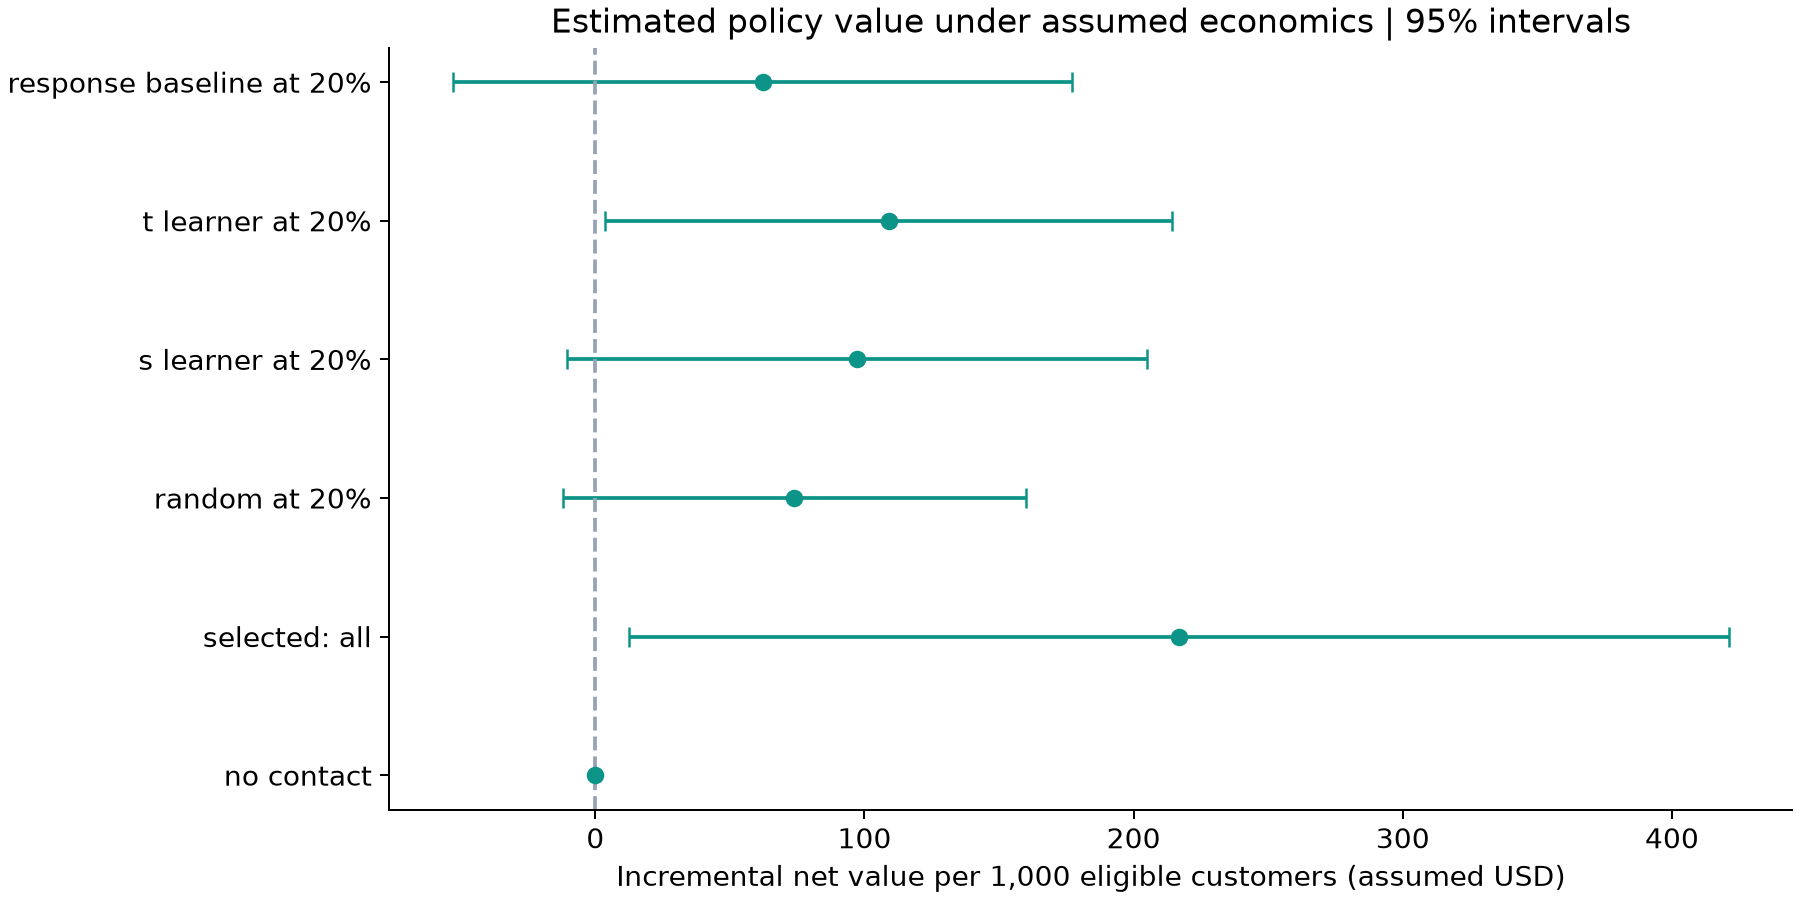

In [5]:
display(summary["config"])
display(summary["selected_on_validation"])
display(pd.read_csv(REPORTS / "policies_test.csv"))
display(Image(filename=str(REPORTS / "figures/policy_value.png")))

## 5. What does the business do next?
IPW estimates incremental net value versus no contact per eligible customer. Approximate intervals condition on fitted models and evaluated masks; they omit training variation and are not multiplicity-adjusted.

In [6]:
display(Markdown(summary["decision"]))
display(pd.DataFrame(summary["paired_test_comparisons"]).T)
display(pd.read_csv(REPORTS / "sensitivity.csv").head(12))

Use contact-all as the candidate for a prospective campaign test under these economics. Validation selected this simple strategy and held-out net value versus no contact is positive with an approximate 95% interval above zero. ML targeting was not selected. Contact-all and random at 100% are the same rule, so their zero paired differences are identities, not failed superiority tests.

,net_per_customer,ci_low,ci_high,net_per_1000
no contact,0.21679,0.012494,0.421086,216.789863
contact all,0.00000,0.000000,0.000000,0.000000
random same coverage,0.00000,0.000000,0.000000,0.000000


,value,cost,label,net_per_customer,ci_low,ci_high,net_per_1000,coverage,incremental_conversions_per_1000
0,20.0,0.01,no contact,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
1,20.0,0.01,contact all,0.116716,0.034998,0.198434,116.715945,1.0,6.335797
2,20.0,0.01,random same coverage,0.116716,0.034998,0.198434,116.715945,1.0,6.335797
3,20.0,0.01,selected: all,0.116716,0.034998,0.198434,116.715945,1.0,6.335797
4,20.0,0.10,no contact,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
5,20.0,0.10,contact all,0.026716,-0.055002,0.108434,26.715945,1.0,6.335797
6,20.0,0.10,random same coverage,0.026716,-0.055002,0.108434,26.715945,1.0,6.335797
7,20.0,0.10,selected: all,0.026716,-0.055002,0.108434,26.715945,1.0,6.335797
8,20.0,0.50,no contact,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
9,20.0,0.50,contact all,-0.373284,-0.455002,-0.291566,-373.284055,1.0,6.335797


## 6. Interview discussion
Why can a positive campaign ATE coexist with no clear advantage for ML? What changes at higher contact costs? Which assumptions cannot be verified in the public extract? How would you design a prospective policy test? See `docs/interview_story.md` for prompts to connect this case study to your actual experience.

## Economic decision maps

Policy and reach are selected on validation separately for each assumed contribution/contact-cost scenario. Test only evaluates those locked plans. This extension follows initial test inspection and is exploratory; pointwise intervals do not adjust for selection or multiple comparisons.

,value,cost,policy,fraction,validation_coverage,validation_net_per_1000,test_net_per_customer,test_ci_low,test_ci_high,test_net_per_1000,test_coverage,test_incremental_conversions_per_1000
0,10.0,0.00,all,1.0,1.000000,77.437522,0.063358,0.022499,0.104217,63.357973,1.000000,6.335797
1,10.0,0.05,all,1.0,1.000000,27.437522,0.013358,-0.027501,0.054217,13.357973,1.000000,6.335797
2,10.0,0.10,response_baseline,0.1,0.099965,15.816027,-0.007650,-0.025470,0.010170,-7.649889,0.099965,0.234659
3,10.0,0.50,none,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,10.0,1.00,none,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,10.0,2.00,none,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,20.0,0.00,all,1.0,1.000000,154.875044,0.126716,0.044998,0.208434,126.715945,1.000000,6.335797
7,20.0,0.05,all,1.0,1.000000,104.875044,0.076716,-0.005002,0.158434,76.715945,1.000000,6.335797
8,20.0,0.10,all,1.0,1.000000,54.875044,0.026716,-0.055002,0.108434,26.715945,1.000000,6.335797
9,20.0,0.50,response_baseline,0.1,0.099965,1.642614,-0.045289,-0.081032,-0.009546,-45.289217,0.099965,0.234659


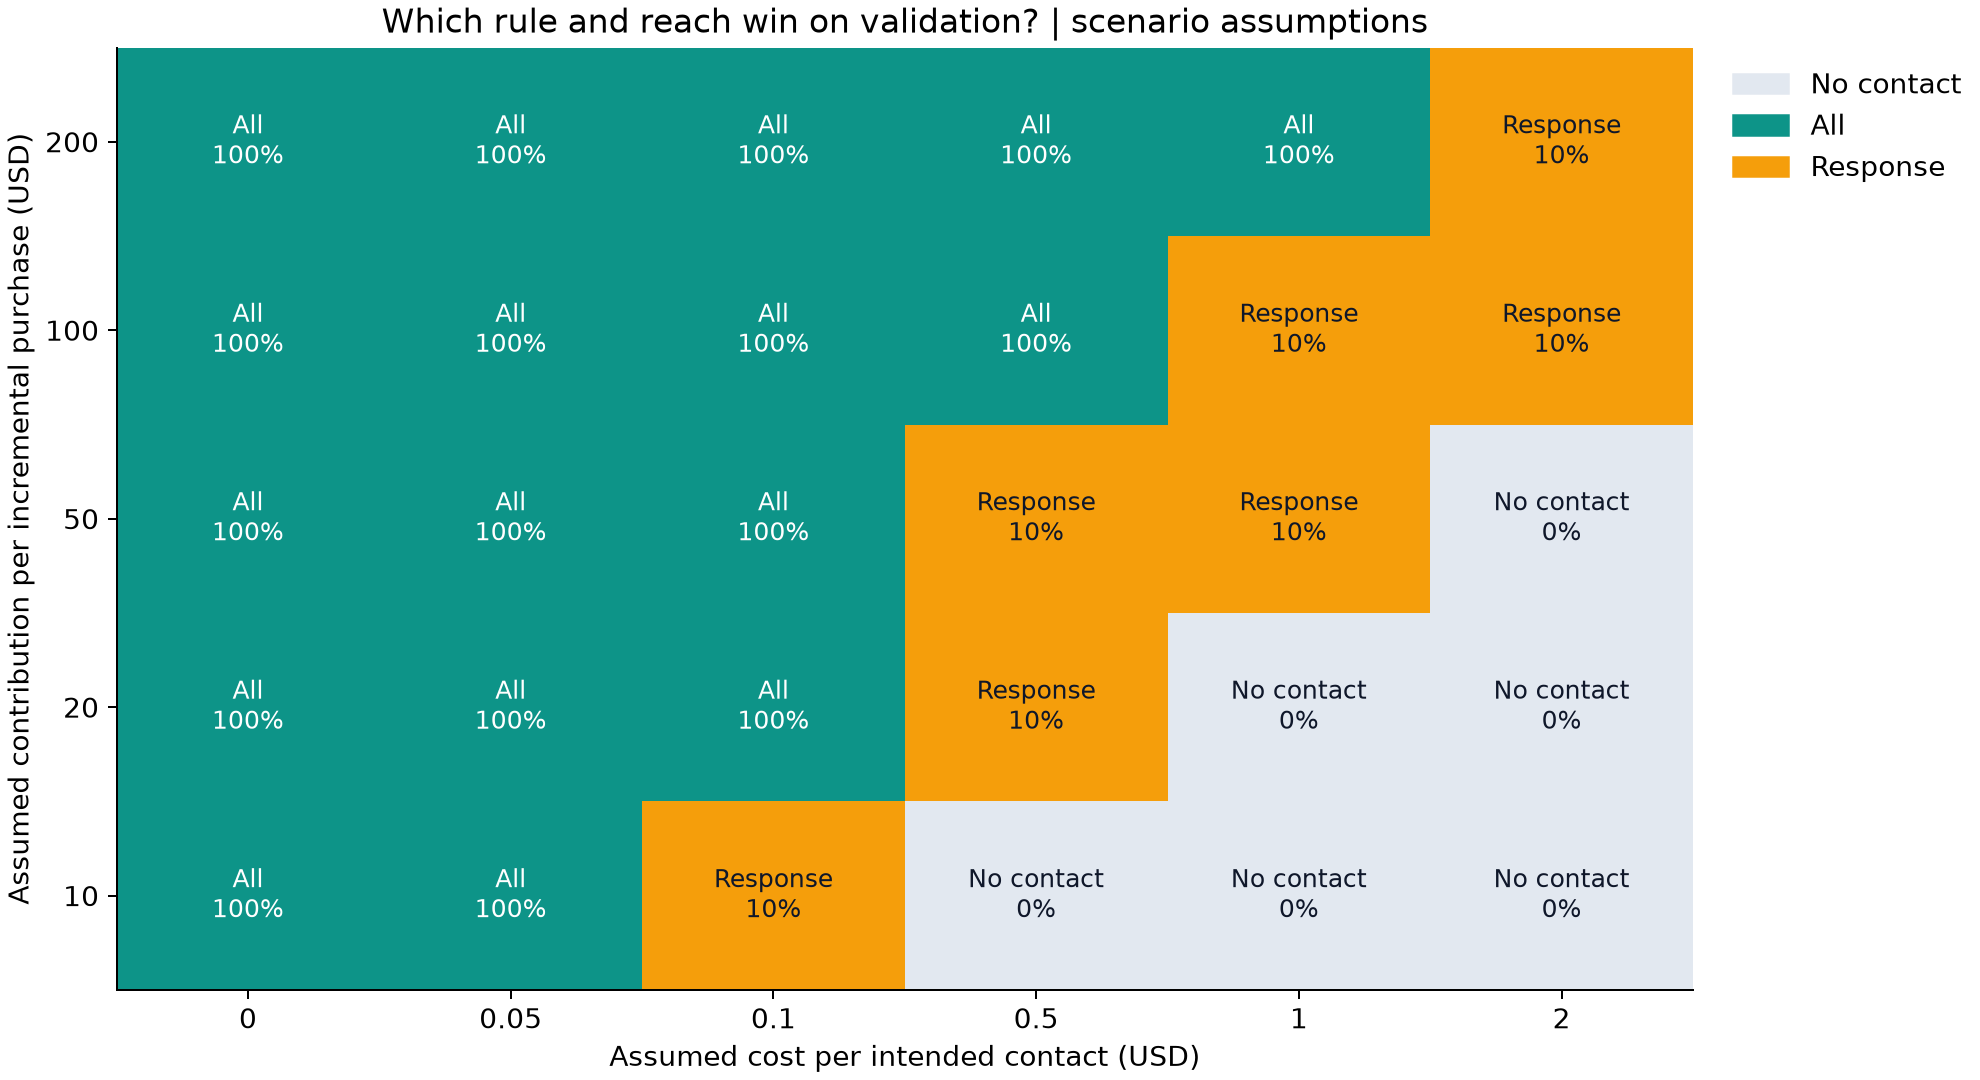

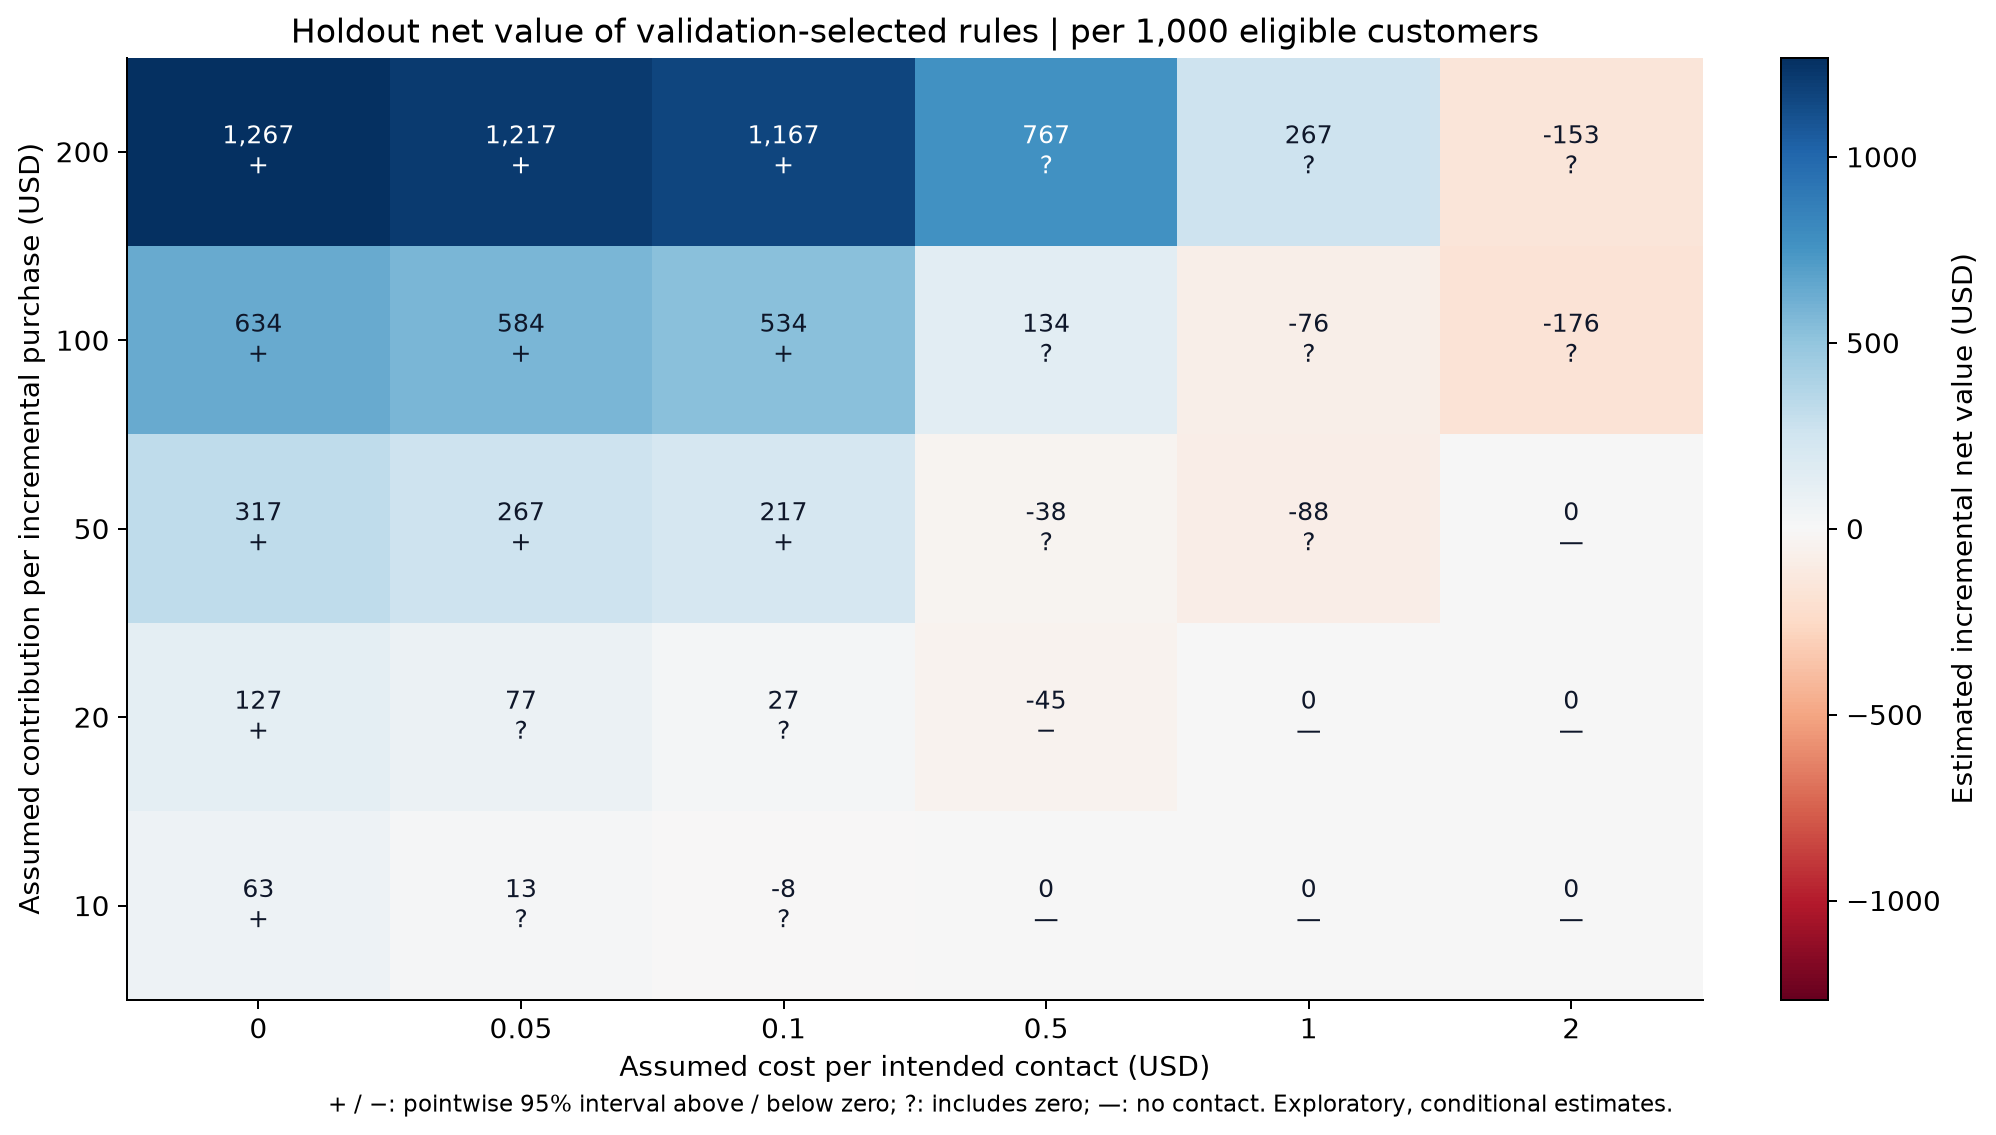

In [7]:
display(pd.read_csv(REPORTS / "economics_scenarios.csv"))
display(Image(filename=str(REPORTS / "figures/decision_map.png")))
display(Image(filename=str(REPORTS / "figures/scenario_value.png")))